Source Node: 1
Destination Node: 6
Shortest Path: 1 -> 3 -> 2 -> 5 -> 6
Minimum Path Cost: 13


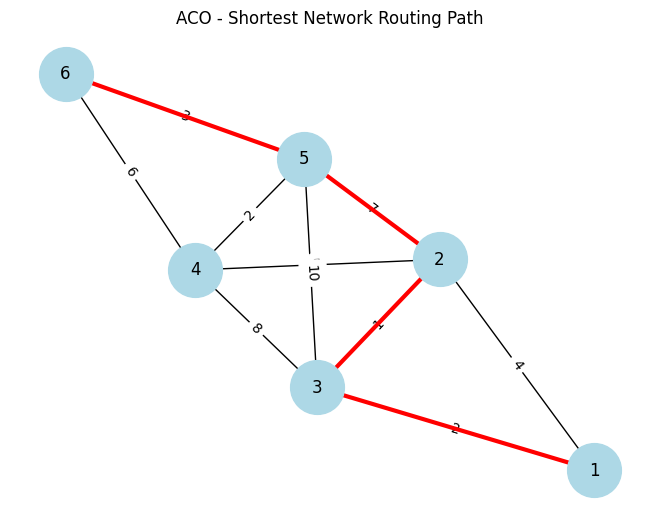

In [2]:
import random
import networkx as nx
import matplotlib.pyplot as plt

graph = {
    1: {2: 4, 3: 2},
    2: {1: 4, 3: 1, 4: 5, 5: 7},
    3: {1: 2, 2: 1, 4: 8, 5: 10},
    4: {2: 5, 3: 8, 5: 2, 6: 6},
    5: {2: 7, 3: 10, 4: 2, 6: 3},
    6: {4: 6, 5: 3}
}

source = 1
destination = 6

ants = 20
iterations = 100
alpha = 1
beta = 2
evaporation = 0.5
Q = 100

pheromone = {}

for node in graph:
    for neighbor in graph[node]:
        pheromone[(node, neighbor)] = 1.0

best_path = None
best_cost = float('inf')

for iteration in range(iterations):

    all_paths = []

    for ant in range(ants):

        current = source
        path = [current]
        visited = {current}
        cost = 0

        while current != destination:

            neighbors = [
                n for n in graph[current]
                if n not in visited
            ]

            if not neighbors:
                break

            probabilities = []

            for neighbor in neighbors:

                tau = pheromone[(current, neighbor)] ** alpha
                eta = (1 / graph[current][neighbor]) ** beta

                probabilities.append(tau * eta)

            total = sum(probabilities)
            probabilities = [p / total for p in probabilities]

            next_node = random.choices(
                neighbors,
                weights=probabilities,
                k=1
            )[0]

            cost += graph[current][next_node]
            path.append(next_node)
            visited.add(next_node)
            current = next_node

        if current == destination:

            all_paths.append((path, cost))

            if cost < best_cost:
                best_cost = cost
                best_path = path

    for edge in pheromone:
        pheromone[edge] *= (1 - evaporation)

    for path, cost in all_paths:

        deposit = Q / cost

        for i in range(len(path) - 1):

            edge = (path[i], path[i + 1])
            pheromone[edge] += deposit

            reverse_edge = (path[i + 1], path[i])
            pheromone[reverse_edge] += deposit

print("Source Node:", source)
print("Destination Node:", destination)

if best_path:
    print("Shortest Path:", " -> ".join(map(str, best_path)))
    print("Minimum Path Cost:", best_cost)
else:
    print("No path found")

G = nx.Graph()

for node in graph:
    for neighbor, weight in graph[node].items():
        G.add_edge(node, neighbor, weight=weight)

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    node_size=1500,
    font_size=12
)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

if best_path:
    best_edges = list(zip(best_path, best_path[1:]))

    nx.draw_networkx_edges(
        G, pos,
        edgelist=best_edges,
        edge_color='red',
        width=3
    )

plt.title("ACO - Shortest Network Routing Path")
plt.show()